# Mechanistic Design Space Exploration for an AND Gate
### Ayush Pandey

We consider three possible mechanisms to achieve the AND gate specification: the HrpR/HrpS $\sigma^{54}$ joint activation circuit, split T7 RNA polymerase complementation, and the InvF/SicA activator and chaperone gate.

In each circuit, two input promoters drive expression of components $Y_1$ and $Y_2$, which associate to form an activating complex $C_3$ that drives reporter production. We assume that binding equilibrates faster than protein expression. The component balances are
$$\dot Y_{i,\mathrm{tot}}=\alpha_i\xi_i-\delta_iY_{i,\mathrm{tot}},\qquad
\dot C_3=k_f(Y_{1,\mathrm{tot}}-C_3)(Y_{2,\mathrm{tot}}-C_3)-k_rC_3,\qquad \dot P=k_{\mathrm{out}}C_3,$$
where $\alpha_i$ and $\delta_i$ are expression and degradation coefficients, $k_f,k_r$ are binding rate constants, and $P$ is the reporter. Let $\xi_i$ be promoter activity in RPU, $T_i$ the total concentration of component $i$ in nM, and $g_i$ the expression gain in nM/RPU. Here $Y_{i,\mathrm{tot}}=Y_i+C_3$ is the total concentration. At equilibrium, $T_i=g_i\xi_i$ with $g_i=\alpha_i/\delta_i$ and
$$KC_3=(T_1-C_3)(T_2-C_3),\qquad K=k_r/k_f,\qquad y=k_{\mathrm{out}}C_3.$$
The output flux $y$ is in nM/min.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch, Rectangle

from biospeak import gate_designs

plt.rcParams.update({"font.size": 16, "pdf.fonttype": 42})
designs = gate_designs()
pd.DataFrame(
    [dict(circuit=g.name, g1=g.gain1, g2=g.gain2, K=g.K, kout=g.kout) for g in designs]
)

,circuit,g1,g2,K,kout
0,HrpR/HrpS,4000,800,250,1.2
1,Split T7,500,700,1200,10.0
2,InvF/SicA,800,4000,250,1.0
3,HrpR/HrpS with HrpV inhibition,4000,800,250,1.2
4,Split T7 with weaker fragment association,500,700,3000,10.0
5,InvF/SicA with SipC competition,800,4000,250,1.0


## Design goal

We express our requirement for the AND logic gate using the following specification contracts on inputs $\xi_1,\xi_2$ and output flux $y$:
$$\begin{aligned}
\mathrm{ON}:&\quad (\xi_1,\xi_2)\in[0.35,0.65]^2, &&y\geq120,\\
\mathrm{OFF1}:&\quad (\xi_1,\xi_2)\in[0.0055,0.07]\times[0.0055,0.65], &&y\leq60,\\
\mathrm{OFF2}:&\quad (\xi_1,\xi_2)\in[0.0055,0.65]\times[0.0055,0.07], &&y\leq60.
\end{aligned}$$

In [2]:
conditions = {
    "ON": ((0.35, 0.65), (0.35, 0.65), "lower", 120.0),
    "OFF1": ((0.0055, 0.07), (0.0055, 0.65), "upper", 60.0),
    "OFF2": ((0.0055, 0.65), (0.0055, 0.07), "upper", 60.0),
}
results, certificates = [], {}
for design in designs:
    for mode, condition in conditions.items():
        result = design.verify(*condition)
        certificates[(design.name, mode)] = result
        results.append(
            dict(
                circuit=design.name,
                mode=mode,
                lower=result["flux_interval"][0],
                upper=result["flux_interval"][1],
                satisfies=result["refines"],
            )
        )
verification = pd.DataFrame(results)
verification.pivot(index="circuit", columns="mode", values="satisfies")

mode,OFF1,OFF2,ON
circuit,,,
HrpR/HrpS,False,False,True
HrpR/HrpS with HrpV inhibition,True,True,True
InvF/SicA,True,False,True
InvF/SicA with SipC competition,True,True,True
Split T7,False,False,True
Split T7 with weaker fragment association,True,True,True


## HrpV inhibition, weaker fragment association, and SipC competition

For HrpR/HrpS, HrpV inhibits reporter production by binding the activating complex. Under fast and strong inhibitor binding, reporter production begins when the complex concentration exceeds the inhibitor total $V_{\mathrm{tot}}$. We select $V_{\mathrm{tot}}=120$ nM.

For split T7, the amino and carboxyl polymerase fragments must associate to restore transcriptional activity. We consider weaker fragment association, represented by a larger dissociation constant $K$. We select $K=3000$ nM.

For InvF/SicA, SipC competes with InvF for binding to SicA. Production, degradation, SipC secretion, and competition for SicA determine the concentration of the transcriptionally active InvF/SicA complex. The input expression contracts determine production fluxes $p_i=\gamma_iT_i$. We select a SipC production flux $p_Z=149.45$ nM/min.

The HrpV reporter relation is
$$y=\begin{cases}0,& C_3\leq V_{\mathrm{tot}},\\
k_{\mathrm{out}}(C_3-V_{\mathrm{tot}}),& C_3>V_{\mathrm{tot}}.
\end{cases}$$

Let $Z$ be the SipC concentration and $C_{2Z}$ the concentration of the SicA and SipC complex. The CRN dynamics of this circuit are
$$\begin{aligned}
\dot Y_1&=p_1-\gamma_1Y_1-k_{12}^+Y_1Y_2+k_{12}^-C_3,\\
\dot Y_2&=p_2-\gamma_2Y_2-k_{12}^+Y_1Y_2+k_{12}^-C_3-k_{2Z}^+Y_2Z+(k_{2Z}^-+k_Z)C_{2Z},\\
\dot Z&=p_Z-\gamma_ZZ-k_{2Z}^+Y_2Z+k_{2Z}^-C_{2Z},\\
\dot C_3&=k_{12}^+Y_1Y_2-(k_{12}^-+\gamma_{12})C_3,\\
\dot C_{2Z}&=k_{2Z}^+Y_2Z-(k_{2Z}^-+\gamma_{2Z}+k_Z)C_{2Z},\\
\dot P&=k_{\mathrm{out}}C_3.
\end{aligned}$$
All $\gamma$ parameters are degradation rates, $k^+$ and $k^-$ are association and dissociation rates, and $k_Z$ is the SipC secretion rate constant. The secretion reaction releases SicA.

The equilibrium balance is
$$p_2=\gamma_2Y_2+
\frac{\gamma_{12}p_1Y_2}{\gamma_1K_{12}+\gamma_{12}Y_2}+
\frac{\gamma_{2Z}p_ZY_2}{\gamma_ZK_{2Z}+(\gamma_{2Z}+k_Z)Y_2},$$
where $K_{12}=(k_{12}^-+\gamma_{12})/k_{12}^+$ and $K_{2Z}=(k_{2Z}^-+\gamma_{2Z}+k_Z)/k_{2Z}^+$. The right hand side is zero at $Y_2=0$, strictly increasing in $Y_2$, and unbounded as $Y_2\to\infty$. Therefore it equals $p_2>0$ at exactly one positive value of $Y_2$, which uniquely determines the remaining concentrations and reporter flux.


In [3]:
expected = [
    [True, False, False],
    [True, False, False],
    [True, True, False],
    [True, True, True],
    [True, True, True],
    [True, True, True],
]
for design, modes in zip(designs, expected):
    assert [
        certificates[(design.name, mode)]["refines"] for mode in conditions
    ] == modes
verification

,circuit,mode,lower,upper,satisfies
0,HrpR/HrpS,ON,276.816705,558.577983,True
1,HrpR/HrpS,OFF1,0.420794,197.292246,False
2,HrpR/HrpS,OFF2,0.420794,61.197860,False
3,Split T7,ON,269.131593,777.363320,True
4,Split T7,OFF1,0.087747,94.762122,False
5,Split T7,OFF2,0.087747,101.834193,False
6,InvF/SicA,ON,230.680587,465.481652,True
7,InvF/SicA,OFF1,0.350662,50.998217,True
8,InvF/SicA,OFF2,0.350662,164.410205,False
9,HrpR/HrpS with HrpV inhibition,ON,132.816705,414.577983,True


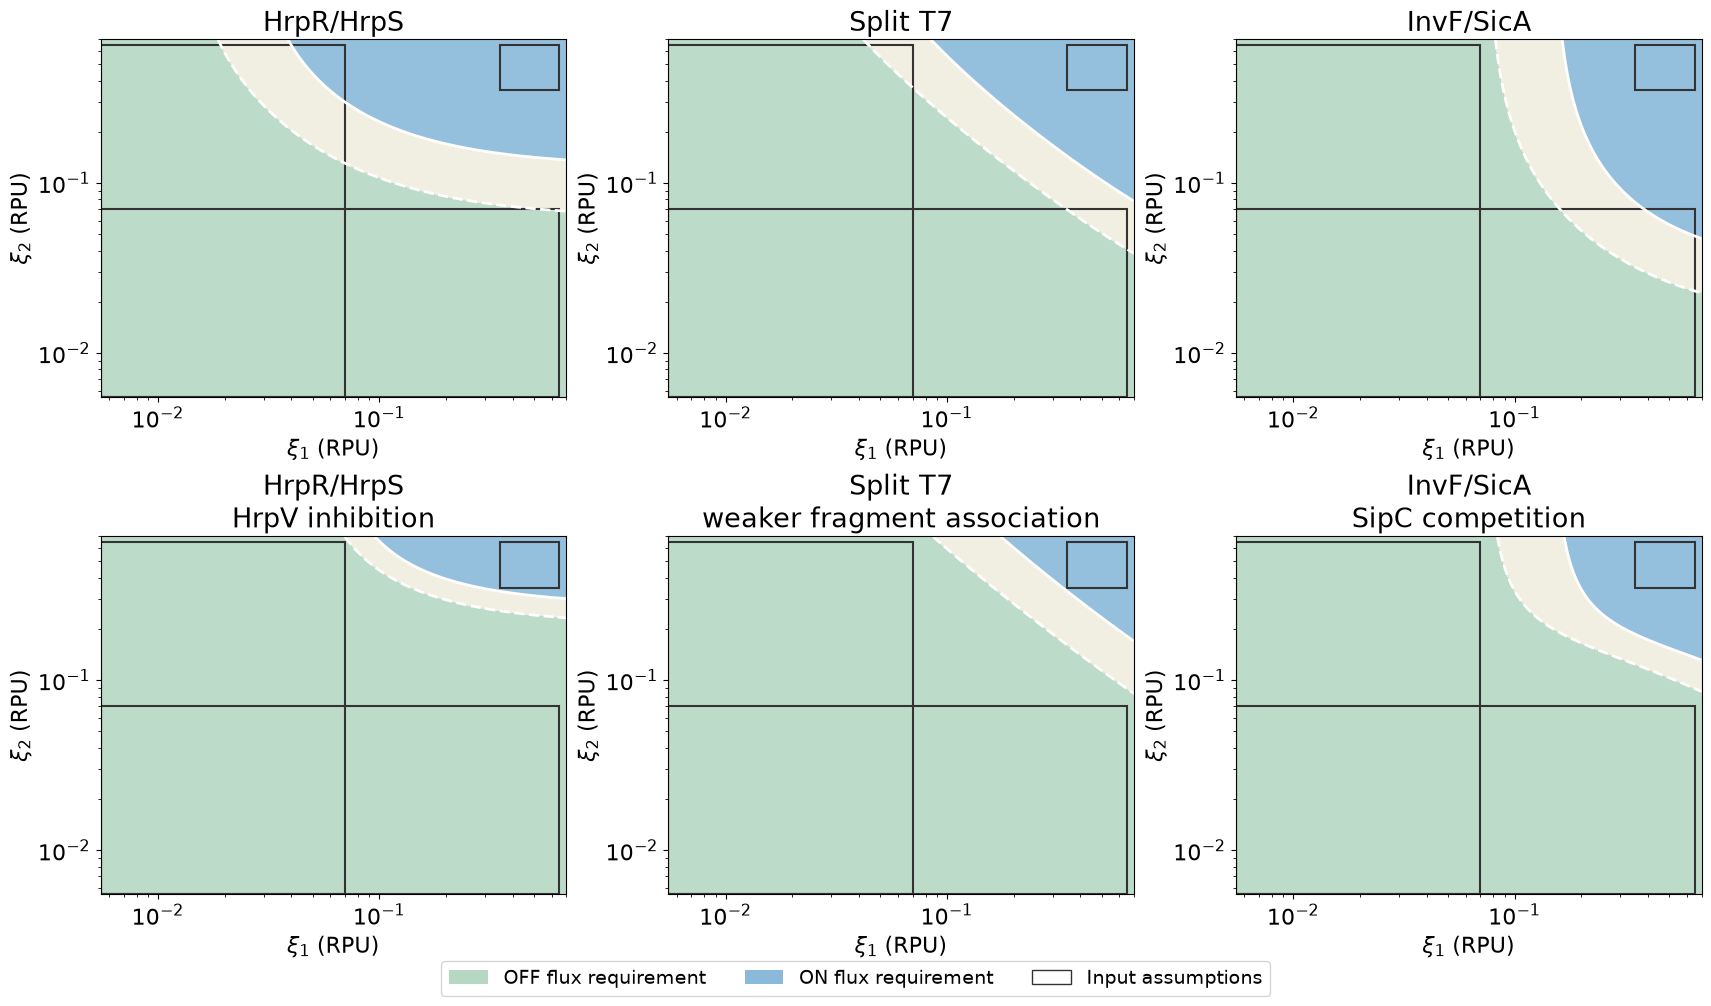

In [4]:
xi = np.geomspace(0.0055, 0.7, 150)
X1, X2 = np.meshgrid(xi, xi)
fig, axes = plt.subplots(2, 3, figsize=(17, 10), layout="constrained")
for ax, design in zip(axes.ravel(), designs):
    flux = design.flux(X1, X2)
    ax.contourf(
        X1,
        X2,
        flux,
        levels=[0, 60, 120, 1e5],
        colors=["#b6d8c3", "#f0eddf", "#8ab9da"],
        alpha=0.9,
    )
    ax.contour(
        X1,
        X2,
        flux,
        levels=[60, 120],
        colors="white",
        linestyles=["--", "-"],
        linewidths=2,
    )
    for bounds1, bounds2, _, _ in conditions.values():
        ax.add_patch(
            Rectangle(
                (bounds1[0], bounds2[0]),
                bounds1[1] - bounds1[0],
                bounds2[1] - bounds2[0],
                fill=False,
                color="0.2",
                lw=1.5,
            )
        )
    ax.set(
        xscale="log",
        yscale="log",
        xlabel=r"$\xi_1$ (RPU)",
        ylabel=r"$\xi_2$ (RPU)",
        title=design.name.replace(" with ", "\n"),
    )
fig.legend(
    handles=[
        Patch(facecolor="#b6d8c3", label="OFF flux requirement"),
        Patch(facecolor="#8ab9da", label="ON flux requirement"),
        Patch(facecolor="none", edgecolor="0.2", label="Input assumptions"),
    ],
    loc="outside lower center",
    ncol=3,
    fontsize=14,
)
plt.show()

## Compositional verification

For each mode, refinement preserves the intended conditional guarantees. A design satisfies the complete specification when its contract refines the specification in every mode.

In [5]:
example = certificates[(designs[3].name, "ON")]
print(example["composed"])
print("Refines ON specification:", example["refines"])

InVars: [z_xi1, z_xi2]
OutVars:[y]
A: [
  -0.9525 z_xi1 <= 1
  2.321 z_xi1 <= -1
  -0.9525 z_xi2 <= 1
  2.321 z_xi2 <= -1
]
G: [
   <= -2.22e-15
  -0.007529 y <= -1
  0.002412 y <= 1
]
Refines ON specification: True
